# Tianhao / Fairy-6b：真实数据、重新训练与完整模型可视化

**2026-11-01更新 · 30分钟恢复确认任务 · EXPLORATORY / 待团队确认**

这份 Notebook 已从“仅数据审查”升级为**实际重新准备特征、训练、验证选参、测试评估与绘图**。
代码和运行输出保存在同一文件中，打开即可阅读；Run All 会建立新的输出目录并重新训练，不覆盖旧实验。

先看第2节数据来源和第3节标签分母，再看第10节开始的模型实验。后半部分含 ROC/PR、混淆矩阵、特征组增益、逻辑回归系数和决策树重要性。

**解释边界：** Release 标签按持续恢复的**确认时点**定义，和 proposal 的“开始时点”不同。
24个选定车道不是全香港道路的代表性样本。曲线与指标是真实队列上的探索结果；不代表科学审批、统计显著性或因果效应。

[数据Release](https://github.com/CityuHK-wyj/hk-traffic-recovery-prediction/releases/tag/data-long-window-2023-2026-v1) · [代码核查报告](../docs/tianhao_proposal_review.md)


**分享版说明：** 本版把工作区路径改成仓库相对路径和 `TIANHAO_WORK_DIR` / `TIANHAO_DATA_DIR`。嵌入输出来自真实重跑。Run All 需要按 `experiments/tianhao/README.md` 下载来源；只核对上传预测请运行 `verify_review.py` 或打开02号Notebook。


## 0. 设置学习参数

`HORIZON` 决定统计15/30/60分钟中的哪一个标签。`EVENT_INDEX` 是按预测时间排序后的事件位置，不是event_id；改变它就能查看另一条真实恢复曲线。统计图使用的已知标签分母会随HORIZON变化。

`HORIZON` 只控制前半部分的数据审查图；后半部分模型实验固定30分钟，与原实验计划一致。

In [1]:
HORIZON = 30        # 可改成15、30、60
EVENT_INDEX = 0     # 可改成0至7596
assert HORIZON in (15, 30, 60)

In [2]:
from pathlib import Path
import os, sys, json, hashlib, subprocess, inspect, uuid
from datetime import datetime, timezone

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p/'pyproject.toml').exists() and (p/'src/traffic_recovery').exists()), None)
if ROOT is None:
    raise FileNotFoundError('请从仓库根目录或notebooks目录打开本notebook。')
REPO = ROOT
WORK = Path(os.environ.get('TIANHAO_WORK_DIR', str(REPO/'data/local/tianhao_experiment'))).expanduser().resolve()
DATA = Path(os.environ.get('TIANHAO_DATA_DIR', str(WORK/'release_subset'))).expanduser().resolve()
RUN = WORK/'notebook_reruns'/('real-model-review-'+datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')+'-'+uuid.uuid4().hex[:6])
FIGURES = RUN/'figures'
FIGURES.mkdir(parents=True)
os.environ.setdefault('MPLCONFIGDIR', str(WORK/'matplotlib_cache'))
sys.path.insert(0, str(REPO/'src'))

import numpy as np
import pandas as pd
import pyarrow.parquet as pq
get_ipython().run_line_magic('matplotlib', 'inline')
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display, Markdown

plt.rcParams.update({'figure.dpi':110, 'savefig.dpi':150,
    'font.family':'DejaVu Sans', 'font.size':10,
    'axes.spines.top':False, 'axes.spines.right':False,
    'axes.titleweight':'bold', 'axes.titlepad':14})
COLORS = {'positive':'#007C83', 'negative':'#64748B', 'unknown':'#D99729',
          'train':'#007C83', 'validation':'#8063A5', 'test':'#C26836'}
LABEL = f'label_{HORIZON}m'
def finish(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES/f'{name}.png', bbox_inches='tight')
    plt.show()
    plt.close(fig)

display(pd.DataFrame({'项目':['Python','项目目录','真实数据目录','本次输出'],
    '位置':[sys.version.split()[0],str(REPO),str(DATA),str(RUN)]}))

,项目,位置
0,Python,3.12.14
1,项目目录,<repository>
2,真实数据目录,<local-workspace>/handoff_r...
3,本次输出,<local-workspace>/experimen...


## 1. 先看版本：代码、数据和结果是三种不同的交付

你的PR #5已经合并到main。长期数据的PR #7与Release要另外看，不能因为main里没有大文件就推断队友没交数据。

刷新仓库时还发现了 `feature/member4-ensemble-models`：新增随机森林和HistGradientBoosting。**它不是XGBoost，也不能仅凭代码存在就声称已有模型成绩。** 下方只读取本地Git元数据，不联网或切换分支。

In [3]:
git_candidates = [REPO/'.venv/bin/git', REPO/'.venv/Scripts/git.exe']
GIT = next((str(p) for p in git_candidates if p.exists()), 'git')
def git(*args):
    return subprocess.check_output([GIT,'-C',str(REPO),*args],text=True).strip()
print('checked-out commit:', git('rev-parse','HEAD'))
print('remote:', git('remote','get-url','origin'))
print('\n本地已获取的远程分支：\n'+git('branch','-r'))
print('\n你的提交：\n'+git('log','--all','--author=Tianhao','--format=%h %an %s'))
print('\n工作区状态：', git('status','--short') or 'clean')

checked-out commit: bb4170a55a4da7cb0298b0ffaa06afa6281d4abe
remote: https://github.com/CityuHK-wyj/hk-traffic-recovery-prediction.git

本地已获取的远程分支：
origin/HEAD -> origin/codex/tianhao-real-data-experiments
  origin/codex/tianhao-real-data-experiments
  origin/main

你的提交：
77896ec Tianhao Wu feat: add external context and model comparison pipeline (#5)

工作区状态： M README.md
 M configs/feature_group_comparison.json
 M docs/external_modeling_progress_report.md
 M src/traffic_recovery/external/calendar.py
 M src/traffic_recovery/models/contract.py
 M src/traffic_recovery/models/evaluation.py
 M tests/test_benchmarks.py
 M tests/test_external_features.py
 M tests/test_model_contract.py
 M tests/test_supervised_models.py
?? docs/tianhao_proposal_review.md
?? experiments/
?? "notebooks/02_Tianhao_\347\234\237\345\256\236\346\250\241\345\236\213\344\270\216\345\244\226\351\203\250\347\211\271\345\276\201\345\256\236\351\252\214.ipynb"
?? "notebooks/03_Tianhao_\347\234\237\345\256\236\351\207\215\

## 2. 验证完整 Release ZIP 与交接表

本次使用已缓存的完整1.67GB数据包；先对照2026-11-01读取的GitHub Release元数据核验整包大小与SHA-256，
再核验已提取文件及内部成员清单。这里不从47GB原始档案重新生成标签，也不把Release说成已有模型效果。


In [4]:
release_meta=json.loads((REPO/'experiments/tianhao/release_metadata.json').read_text(encoding='utf-8'))
SOURCE_CACHE=WORK/'sources'
TRAFFIC_ZIP=SOURCE_CACHE/'traffic_prepared.zip'
asset=next(a for a in release_meta['assets'] if a['name']=='HK_Traffic_Long_Window_Prepared_Data.zip')
with TRAFFIC_ZIP.open('rb') as stream:
    release_sha=hashlib.file_digest(stream,'sha256').hexdigest()
assert TRAFFIC_ZIP.stat().st_size==asset['size']
assert 'sha256:'+release_sha==asset['digest']
(RUN/'release_metadata.json').write_text(json.dumps(release_meta,indent=2),encoding='utf-8')
print('Full Release ZIP verified:', TRAFFIC_ZIP.stat().st_size, 'bytes; SHA256', release_sha)
shared_manifest = json.loads((DATA/'SHARED_DATA_MANIFEST.json').read_text())
checked = []
for relative, expected in shared_manifest['files'].items():
    path = DATA/relative
    if path.is_file():
        actual = hashlib.file_digest(path.open('rb'), 'sha256').hexdigest()
        assert actual == expected['sha256'], f'文件校验失败：{relative}'
        assert path.stat().st_size == expected['bytes']
        checked.append({'文件':relative, '字节数':path.stat().st_size, 'SHA256核验':'passed'})
events = pd.read_parquet(DATA/'processed/derived/events.parquet')
csv_events = pd.read_csv(DATA/'reports/events_review.csv', dtype={'event_id':'string'})
assert len(events)==len(csv_events)==7597
assert set(events.event_id)==set(csv_events.event_id)
for h in (15,30,60):
    a=events.set_index('event_id')[f'label_{h}m'].astype('Float64').sort_index()
    b=csv_events.set_index('event_id')[f'label_{h}m'].astype('Float64').sort_index()
    assert np.allclose(a.to_numpy(dtype=float,na_value=np.nan), b.to_numpy(dtype=float,na_value=np.nan), equal_nan=True)
events = events.sort_values(['prediction_time','event_id']).reset_index(drop=True)
for col in ['prediction_time','feature_max_available_at','onset_time','onset_confirmed_at',
            'recovery_time','recovery_available_at','followup_end','episode_separated_at','reference_fit_end','outcome_maturity_at']:
    if col in events:
        events[col]=pd.to_datetime(events[col],utc=True).dt.tz_convert('Asia/Hong_Kong')
print(f'已验证 {len(checked)} 个源文件；Parquet与CSV的事件ID及三种标签一致。')
display(pd.DataFrame(checked))
display(events[['event_id','detector_id','direction','lane_id','prediction_time',
                'speed_kmh','baseline_kmh','speed_ratio',LABEL,'split_proposal']].head(8))

Full Release ZIP verified: 1669288966 bytes; SHA256 53688e6e095798f50c124376da1f0f354ca4b2aedf9e83e960fef04fc7298bc9


已验证 17 个源文件；Parquet与CSV的事件ID及三种标签一致。


,文件,字节数,SHA256核验
0,processed/derived/cohort_bins.parquet,215932031,passed
1,processed/derived/events.parquet,714791,passed
2,reports/archive_anomalies.csv,887,passed
3,reports/cohort.csv,2320,passed
4,reports/cohort_selection.csv,3190,passed
5,reports/coverage_detector_month.csv,102040,passed
6,reports/coverage_lane_day.csv,19205493,passed
7,reports/coverage_lane_period.csv,4755,passed
8,reports/events_review.csv,3589180,passed
9,reports/excluded_reference_units.csv,2,passed


,event_id,detector_id,direction,lane_id,prediction_time,speed_kmh,baseline_kmh,speed_ratio,label_30m,split_proposal
0,a1be8743b14f9ffa69d5,AID01117,North,Fast Lane,2023-02-01 08:00:00+08:00,10.0,71.0,0.140845,1,train
1,5c7d0cdd9345c6b097cb,AID01108,North West,Fast Lane,2023-02-01 08:10:00+08:00,15.0,74.0,0.202703,0,train
2,a65b60b7ce5ba057a988,AID01117,North,Fast Lane,2023-02-01 15:20:00+08:00,15.5,71.0,0.218310,0,train
3,e84d5c330d0d713a916b,AID01108,North West,Fast Lane,2023-02-01 15:55:00+08:00,10.5,74.0,0.141892,0,train
4,0d8022f65df2fad3ae3b,AID01117,North,Fast Lane,2023-02-02 08:00:00+08:00,16.0,71.0,0.225352,1,train
5,cc41e1c4f9a96b959cd9,AID01106,South East,Fast Lane,2023-02-02 08:10:00+08:00,19.5,58.0,0.336207,0,train
6,47314dd533d763ddeabc,AID01108,North West,Fast Lane,2023-02-02 08:30:00+08:00,16.0,74.0,0.216216,0,train
7,d7ab9678efad89176a80,AID01108,North West,Fast Lane,2023-02-02 15:45:00+08:00,11.5,74.0,0.155405,0,train


### 一行究竟是什么？

这里每行是一个**检测器＋方向＋车道上的可见拥堵起点事件**，不是一条原始交通观测，也不是已经验证的独立道路事故。

| 字段 | 理解方式 | 能否作为预测输入 |
|---|---|---|
| event_id | 本次拥堵的标识 | 作为连接键，不是数值特征 |
| prediction_time | 当时可以作出预测的时刻 | 用于时间划分及日历特征 |
| speed_kmh / speed_ratio | 预测时已知速度／相对正常速度 | 在可获取时间验证后使用 |
| baseline_kmh | 用2023年1月历史拟合的参考速度 | 已有训练历史依据 |
| label_30m | 30分钟范围是否观察到恢复确认 | 目标y |
| recovery_time / followup_end | 后续恢复及观测结果 | 结果审查字段，不能作为X |
| outcome_maturity_at | 结果何时足够成熟 | 用于隔离划分，不能作为X |

**思考：** 如果把所有列直接交给分类器，它会不会从recovery_time“偷看答案”？

## 3. 检查标签和时间划分

图表用数量展示已恢复、未恢复和未知；黄色未知不能被当成负例。预测范围越长，需要越长的后续观测，因此未知样本数可能增加。

,horizon,events,positive,negative,unknown,known
split,,,,,,
train,30,3833,1449,1979,405,3428
validation,30,2235,890,1118,227,2008
test,30,1529,629,734,166,1363


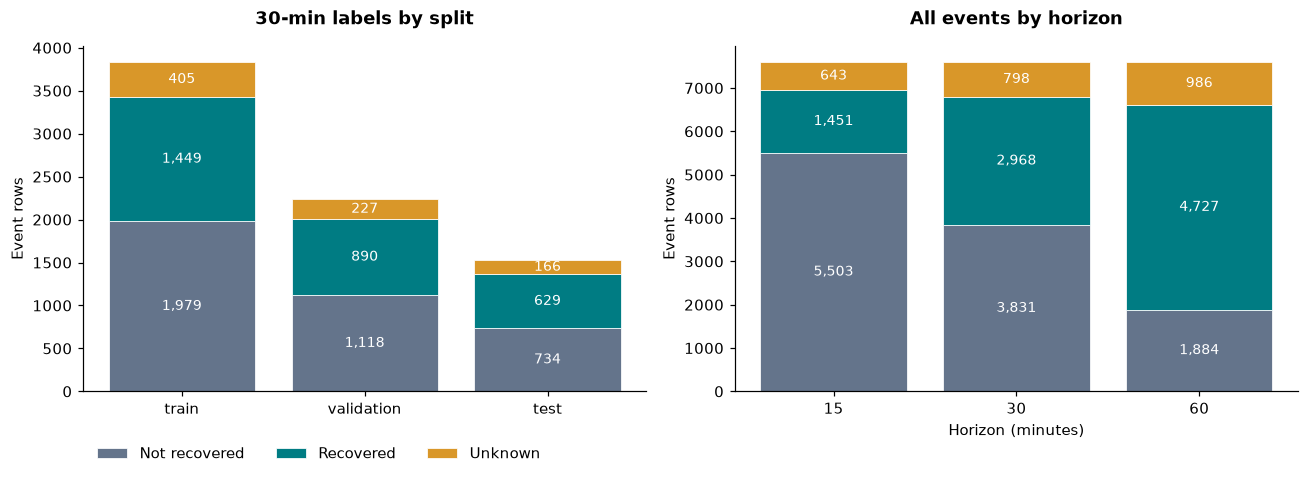

In [5]:
split_order=['train','validation','test']
counts=[]
for split in split_order:
    part=events.loc[events.split_proposal.eq(split)]
    for h in (15,30,60):
        y=part[f'label_{h}m']
        counts.append({'split':split,'horizon':h,'events':len(part),
            'positive':int(y.eq(1).sum()),'negative':int(y.eq(0).sum()),
            'unknown':int(y.isna().sum()),'known':int(y.notna().sum())})
counts=pd.DataFrame(counts)
counts.to_csv(RUN/'label_counts.csv',index=False)
display(counts.query('horizon == @HORIZON').set_index('split'))
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
for ax,table,title in [
    (axes[0],counts.query('horizon == @HORIZON').set_index('split'),f'{HORIZON}-min labels by split'),
    (axes[1],counts.groupby('horizon')[['positive','negative','unknown']].sum(),'All events by horizon')]:
    base=np.zeros(len(table))
    for key,label in [('negative','Not recovered'),('positive','Recovered'),('unknown','Unknown')]:
        vals=table[key].to_numpy()
        ax.bar(np.arange(len(table)),vals,bottom=base,color=COLORS[key],label=label,edgecolor='white',linewidth=.5)
        for i,(v,b) in enumerate(zip(vals,base)):
            if v: ax.text(i,b+v/2,f'{v:,}',ha='center',va='center',color='white',fontsize=9)
        base+=vals
    ax.set_xticks(np.arange(len(table)),table.index.astype(str))
    ax.set_ylabel('Event rows'); ax.set_title(title)
axes[1].set_xlabel('Horizon (minutes)')
axes[0].legend(loc='upper left',bbox_to_anchor=(0,-.12),ncol=3,frameon=False)
finish(fig,'01_labels_and_unknowns')

**读图结论：** 30分钟标签有6,799条已知、798条未知。不同范围的可用样本不一样，不能只写“样本量7,597”而省略实际评估分母。下面的事件数只是当前24车道队列中的已检测事件，不代表全香港交通拥堵总量。

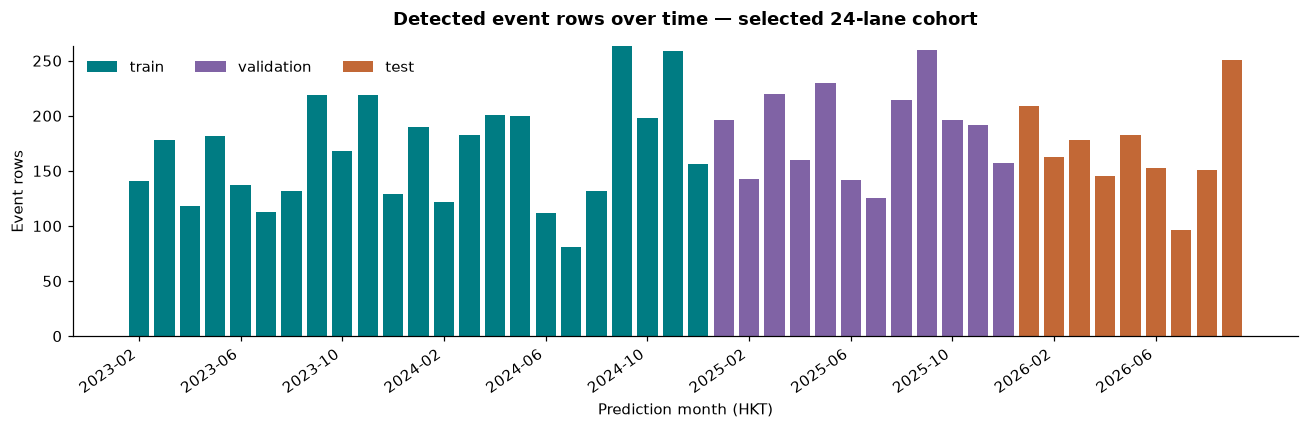

,events,start,end
split_proposal,,,
train,3833,2023-02-01 08:00:00+08:00,2024-12-31 18:35:00+08:00
validation,2235,2025-01-02 19:00:00+08:00,2025-12-31 18:10:00+08:00
test,1529,2026-01-01 17:50:00+08:00,2026-09-30 18:30:00+08:00


In [6]:
events['month']=events.prediction_time.dt.tz_localize(None).dt.to_period('M').astype(str)
months=pd.period_range('2023-02','2026-09',freq='M').astype(str)
monthly=pd.crosstab(events.month,events.split_proposal).reindex(index=months,columns=split_order,fill_value=0)
fig,ax=plt.subplots(figsize=(12,4))
bottom=np.zeros(len(monthly))
for split in split_order:
    ax.bar(np.arange(len(monthly)),monthly[split],bottom=bottom,label=split,color=COLORS[split])
    bottom+=monthly[split].to_numpy()
ticks=np.arange(0,len(monthly),4)
ax.set_xticks(ticks,monthly.index[ticks],rotation=35,ha='right')
ax.set(title='Detected event rows over time — selected 24-lane cohort',ylabel='Event rows',xlabel='Prediction month (HKT)')
ax.legend(frameon=False,ncol=3)
finish(fig,'02_monthly_events')
display(events.groupby('split_proposal').agg(events=('event_id','size'),start=('prediction_time','min'),end=('prediction_time','max')).reindex(split_order))

## 4. 按现有接口验证：为什么旧配置不能直接使用？

你的 `models/contract.py` 会检查唯一键、时区、标签及时间边界。先让它检查原来的短pilot配置，预期会失败；然后建立**仅供本notebook审查**的长期边界配置，并保留pending状态。原仓库配置不被覆盖。

这一步只验证接口与部分防泄漏规则，**不会证明标签科学定义正确，也不会替代小组确认**。

In [7]:
from traffic_recovery.models.contract import ExperimentContract, validate_event_table
from traffic_recovery.models.dataset import build_model_dataset

frame=events.copy()
frame['split']=frame.split_proposal.astype('string')
old_contract=ExperimentContract.from_path(REPO/'configs/experiment_contract.json')
try:
    validate_event_table(frame,old_contract)
except ValueError as exc:
    print('预期中的旧配置失败：',exc)
else:
    raise AssertionError('旧配置意外通过，请重新审查数据及边界。')

payload=json.loads((REPO/'configs/experiment_contract.json').read_text())
payload['version']='long-window-learning-review-v1'
payload['scientific_approval']='pending_team_review_not_final_results'
payload['split_boundaries']={'validation_start':'2025-01-01T00:00:00+08:00',
    'test_start':'2026-01-01T00:00:00+08:00','test_end':'2026-10-01T00:00:00+08:00'}
contract_path=RUN/'review_contract.json'
contract_path.write_text(json.dumps(payload,indent=2))
contract=ExperimentContract.from_path(contract_path)
validation=validate_event_table(frame,contract)
for split,boundary in [('train',contract.validation_start),('validation',contract.test_start)]:
    selected=frame.loc[frame.split.eq(split)]
    assert selected.outcome_maturity_at.notna().all()
    assert (selected.outcome_maturity_at < boundary).all()
assert events.event_id.is_unique
assert (events.feature_max_available_at <= events.prediction_time).all()
local_dataset,dataset_report=build_model_dataset(frame,contract)
local_dataset.to_parquet(RUN/'local_event_features_REVIEW_ONLY.parquet',index=False)
display(pd.DataFrame([validation]))
print('原dataset builder执行成功；事件数：',len(local_dataset))
print('本次local输入白名单：',list(contract.feature_groups['local']))
print('以上是local接口审查；第10节将重新生成并加入真实日历、温度与风速。事故、活动和邻路仍未通过来源/映射门槛。')

预期中的旧配置失败： A non-purged split crosses a configured temporal boundary


,rows,events,purged,known_label_15m,known_label_30m,known_label_60m
0,7597,7597,0,6954,6799,6611


原dataset builder执行成功；事件数： 7597
本次local输入白名单： ['speed_kmh', 'speed_ratio', 'baseline_kmh', 'valid_slots', 'onset_observed_minutes']
以上是local接口审查；第10节将重新生成并加入真实日历、温度与风速。事故、活动和邻路仍未通过来源/映射门槛。


## 5. 看真实恢复曲线，理解标签与未来数据

当前交接规则：速度/参考速度≤0.5的两个连续可用分箱确认拥堵；≥0.8的三个连续可用分箱确认恢复。预测时点包含分箱结束后10分钟的保守可获取延迟。标签按**恢复确认时刻**是否进入预测范围生成。

这与proposal的“持续恢复开始时刻”并不完全相同。图上同时画出观测时间和信息可获取时间，便于你判断这个定义是否符合最终研究问题。

下图预测后的速度仅用于**事后解释标签**；黄色区域的数据禁止作为该事件在预测时刻的输入。缺失分箱保留断线，不插值。 **横轴是观测分箱结束时刻，并非可获取时刻。预测竖线左侧也不能全部直接用作输入：例如07:55的分箱要到08:05才可获取。当前事件的实际速度特征来自onset_confirmed_at对应分箱；请同时检查表中的available_at。**

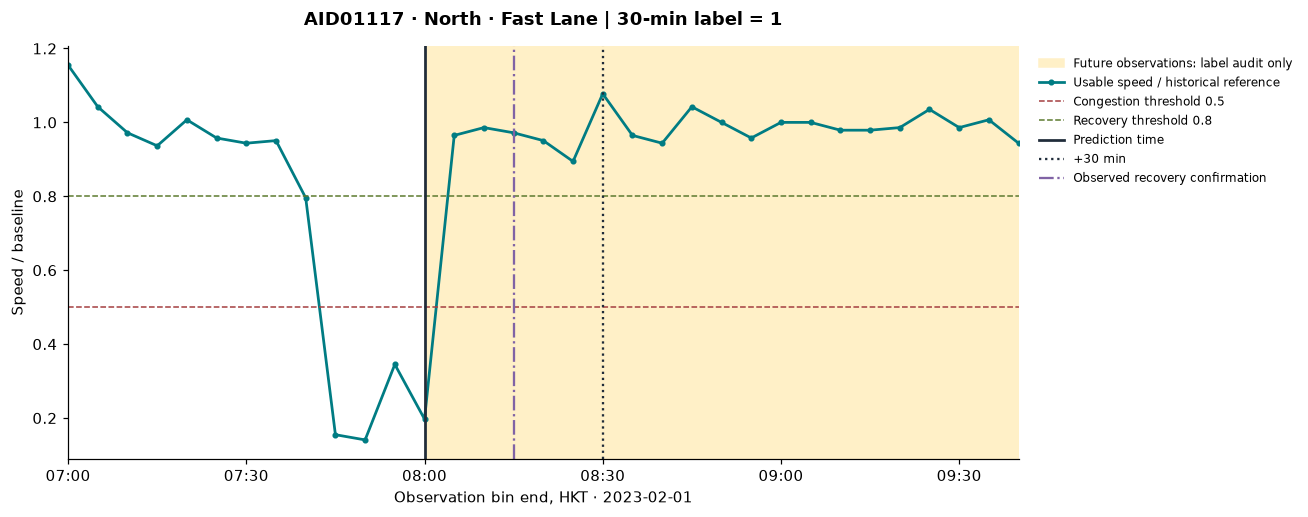

,本事件
event_id,a1be8743b14f9ffa69d5
prediction_time,2023-02-01 08:00:00+08:00
onset_confirmed_at,2023-02-01 07:50:00+08:00
recovery_time,2023-02-01 08:15:00+08:00
recovery_available_at,2023-02-01 08:25:00+08:00
followup_end,2023-02-01 08:15:00+08:00
termination_reason,recovered
label_30m,1
reason_30m,confirmed_recovery


,timestamp,available_at,speed_kmh,usable,ratio
0,2023-02-01 07:00:00+08:00,2023-02-01 07:10:00+08:00,82.0,True,1.154930
1,2023-02-01 07:05:00+08:00,2023-02-01 07:15:00+08:00,74.0,True,1.042254
2,2023-02-01 07:10:00+08:00,2023-02-01 07:20:00+08:00,69.0,True,0.971831
3,2023-02-01 07:15:00+08:00,2023-02-01 07:25:00+08:00,66.5,True,0.936620
4,2023-02-01 07:20:00+08:00,2023-02-01 07:30:00+08:00,71.5,True,1.007042
5,2023-02-01 07:25:00+08:00,2023-02-01 07:35:00+08:00,68.0,True,0.957746
6,2023-02-01 07:30:00+08:00,2023-02-01 07:40:00+08:00,67.0,True,0.943662
7,2023-02-01 07:35:00+08:00,2023-02-01 07:45:00+08:00,67.5,True,0.950704


In [8]:
assert 0 <= EVENT_INDEX < len(events)
event=events.iloc[EVENT_INDEX]
start=event.prediction_time-pd.Timedelta(minutes=60)
end=event.prediction_time+pd.Timedelta(minutes=100)
bin_path=DATA/'processed/derived/cohort_bins.parquet'
bin_columns=['detector_id','direction','lane_id','timestamp','available_at','speed_kmh','usable']
curve=pd.read_parquet(bin_path,columns=bin_columns,filters=[
    ('detector_id','==',event.detector_id),('direction','==',event.direction),('lane_id','==',event.lane_id),
    ('timestamp','>=',start),('timestamp','<=',end)])
curve=curve.sort_values('timestamp')
assert not curve.timestamp.duplicated().any()
curve['ratio']=curve.speed_kmh/event.baseline_kmh
curve['plot_ratio']=curve.ratio.where(curve.usable)
timeline=curve.set_index('timestamp').reindex(pd.date_range(start,end,freq='5min'))
fig,ax=plt.subplots(figsize=(12,4.8))
ax.axvspan(event.prediction_time,end,color='#FFF0C7',label='Future observations: label audit only')
ax.plot(timeline.index,timeline.plot_ratio,color=COLORS['positive'],lw=1.8,marker='o',ms=3,label='Usable speed / historical reference')
ax.axhline(.5,color='#A43E40',ls='--',lw=1,label='Congestion threshold 0.5')
ax.axhline(.8,color='#5D7A2F',ls='--',lw=1,label='Recovery threshold 0.8')
ax.axvline(event.prediction_time,color='#202C3A',lw=1.8,label='Prediction time')
ax.axvline(event.prediction_time+pd.Timedelta(minutes=HORIZON),color='#202C3A',ls=':',label=f'+{HORIZON} min')
if pd.notna(event.recovery_time) and start<=event.recovery_time<=end:
    ax.axvline(event.recovery_time,color='#8063A5',lw=1.5,ls='-.',label='Observed recovery confirmation')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M',tz=event.prediction_time.tz))
ax.set(xlim=(start,end),ylabel='Speed / baseline',xlabel=f'Observation bin end, HKT · {event.prediction_time.date()}',
    title=f'{event.detector_id} · {event.direction} · {event.lane_id} | {HORIZON}-min label = {event[LABEL]}')
ax.legend(loc='upper left',bbox_to_anchor=(1.01,1),frameon=False,fontsize=8)
finish(fig,'03_real_event_curve')
display(event[['event_id','prediction_time','onset_confirmed_at','recovery_time','recovery_available_at',
              'followup_end','termination_reason',LABEL,f'reason_{HORIZON}m']].to_frame('本事件'))
display(curve[['timestamp','available_at','speed_kmh','usable','ratio']].head(8))

**如何读这一例：** 先看预测竖线，再看所选范围的截止线，最后看恢复确认线。正类只说明交接规则观察到恢复确认，不等于事故清除，也不证明精确物理恢复时刻。

你可以回到第0节，把EVENT_INDEX改成另一行再重跑本节。事件表的未知标签需要结合termination_reason解释。

## 6. 训练数据中的速度特征是什么样？

这里只用train画直方图，避免用测试结果指导特征选择。分布归一化便于比较两类的形状，图例同时保留真实样本量。未知标签不混入任何一类。

分布差异是描述性现象，不证明该特征的预测力或因果作用。

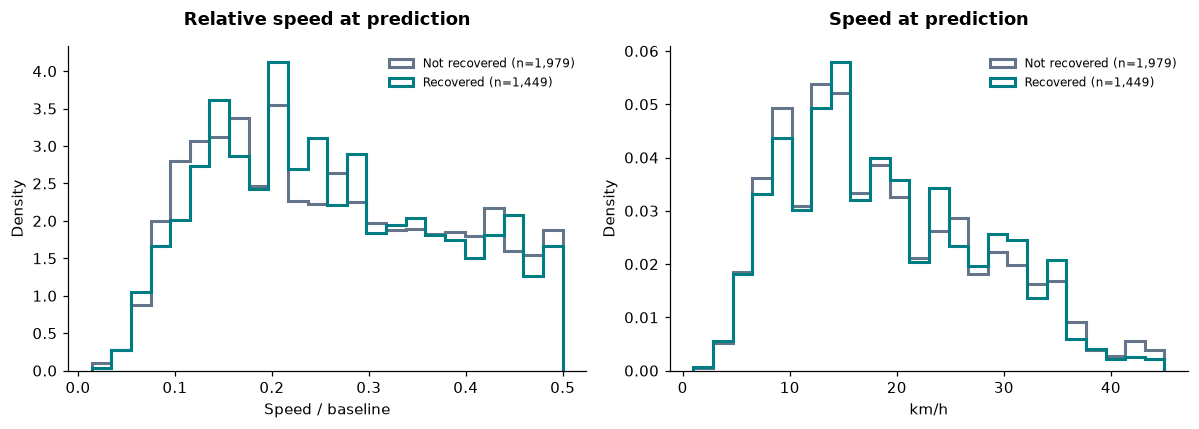

speed_ratio           speed_kmh        baseline_kmh         \
                count    median     count median        count median   
label_30m                                                              
0                1979  0.243243      1979   17.0         1979   71.0   
1                1449  0.246479      1449   17.5         1449   71.0   

          valid_slots         
                count median  
label_30m                     
0                1979    8.0  
1                1449    8.0

In [9]:
train=events.loc[events.split_proposal.eq('train') & events[LABEL].notna()].copy()
fig,axes=plt.subplots(1,2,figsize=(11,4))
for ax,column,title in [(axes[0],'speed_ratio','Relative speed at prediction'),(axes[1],'speed_kmh','Speed at prediction')]:
    edges=np.linspace(train[column].min(),train[column].max(),25)
    for label,key,name in [(0,'negative','Not recovered'),(1,'positive','Recovered')]:
        sample=train.loc[train[LABEL].eq(label),column].dropna()
        ax.hist(sample,bins=edges,density=True,histtype='step',lw=2,color=COLORS[key],label=f'{name} (n={len(sample):,})')
    ax.set(title=title,xlabel='Speed / baseline' if column=='speed_ratio' else 'km/h',ylabel='Density')
    ax.legend(frameon=False,fontsize=8)
finish(fig,'04_train_feature_distributions')
display(train.groupby(LABEL)[['speed_ratio','speed_kmh','baseline_kmh','valid_slots']].agg(['count','median']))

## 7. 日历适配器的空源边界演示

本节故意传空假期表，验证“未知不等于非假期”。这是在真实事件上的接口演示，**不是最终实验日历**。
第10节会从已保存的官方年度公告重新解析真实假期，再用于训练。小时事件数只描述队列，不是恢复率。


,event_id,prediction_time,hour_sin,hour_cos,is_weekend,is_public_holiday,calendar_source_observed
0,a1be8743b14f9ffa69d5,2023-02-01 08:00:00+08:00,0.866025,-0.500000,False,<NA>,False
1,5c7d0cdd9345c6b097cb,2023-02-01 08:10:00+08:00,0.843391,-0.537300,False,<NA>,False
2,a65b60b7ce5ba057a988,2023-02-01 15:20:00+08:00,-0.766044,-0.642788,False,<NA>,False
3,e84d5c330d0d713a916b,2023-02-01 15:55:00+08:00,-0.854912,-0.518773,False,<NA>,False
4,0d8022f65df2fad3ae3b,2023-02-02 08:00:00+08:00,0.866025,-0.500000,False,<NA>,False
5,cc41e1c4f9a96b959cd9,2023-02-02 08:10:00+08:00,0.843391,-0.537300,False,<NA>,False
6,47314dd533d763ddeabc,2023-02-02 08:30:00+08:00,0.793353,-0.608761,False,<NA>,False
7,d7ab9678efad89176a80,2023-02-02 15:45:00+08:00,-0.831470,-0.555570,False,<NA>,False


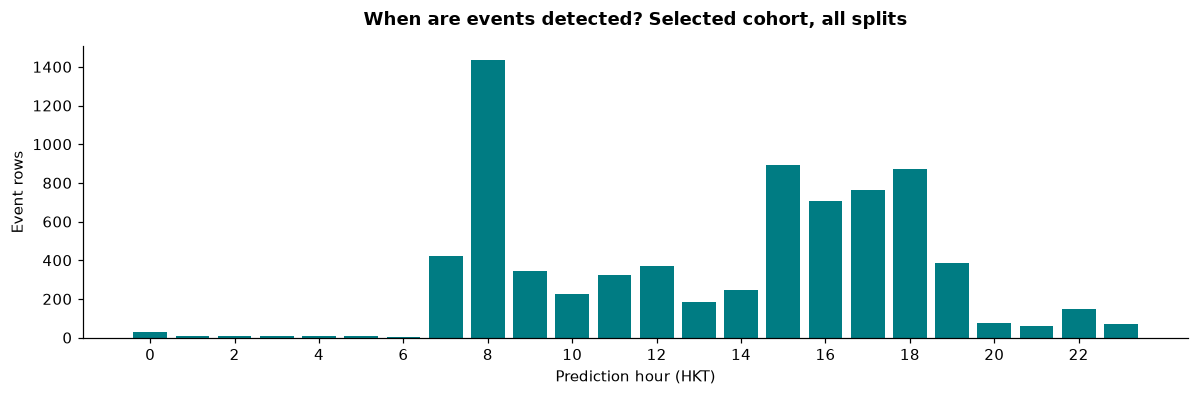

小时事件数不是恢复率，也不是全香港交通流量。


In [10]:
from traffic_recovery.external.calendar import calendar_features
holiday_columns=['holiday_id','local_date','holiday_name','available_at',
                 'source_url','source_retrieved_at','source_sha256']
empty_holidays=pd.DataFrame(columns=holiday_columns)
calendar_demo=calendar_features(events.head(30)[['event_id','prediction_time']],empty_holidays)
assert calendar_demo.is_public_holiday.isna().all()
assert not calendar_demo.calendar_source_observed.any()
calendar_demo.to_csv(RUN/'calendar_adapter_30_real_events.csv',index=False)
display(calendar_demo[['event_id','prediction_time','hour_sin','hour_cos','is_weekend',
                       'is_public_holiday','calendar_source_observed']].head(8))
hours=events.prediction_time.dt.hour.value_counts().reindex(range(24),fill_value=0)
fig,ax=plt.subplots(figsize=(11,3.7))
ax.bar(hours.index,hours.values,color=COLORS['positive'])
ax.set(xticks=range(0,24,2),xlabel='Prediction hour (HKT)',ylabel='Event rows',
       title='When are events detected? Selected cohort, all splits')
finish(fig,'05_hourly_event_counts')
print('小时事件数不是恢复率，也不是全香港交通流量。')

## 8. 空间模块的真实状态：候选匹配仍需验证

按检测器ID连接当前元数据只能用于位置审查；不能证明该位置和方向在过去几年一直有效。候选匹配有route_id也不代表已验证。

下图第一部分展示已有元数据审查中的方向差异；第二部分展示旧40事件空间审查状态。**两个图的数据队列不同，不能把旧空间表拼进长期模型。**

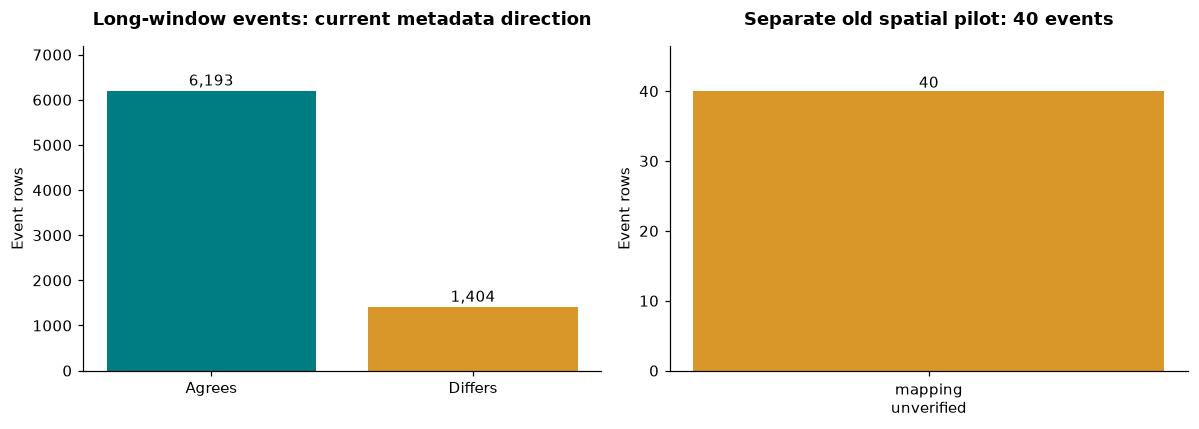

,detector_id,direction,Direction,Road_EN
15,AID01111,North East,East,Hong Chong Road near The Hong Kong Polytechnic...
16,AID01107,North East,South East,Aberdeen Tunnel near Wong Chuk Hang Hospital -...
41,AID01114,North East,North,Princess Margaret Road near Oi Man Estate - No...
58,AID01124,North East,South East,Lion Rock Tunnel Road near Toll Plaza - Northb...
205,AID01112,North East,East,Hong Chong Road near The Hong Kong Polytechnic...
405,AID01129,North East,East,Sha Tin Road near Pok Hong Estate - Northbound


方向差异仅是待审查信号；不能据此认定某个源错误，也不能代表空间特征已可用。


In [11]:
metadata=pd.read_csv(DATA/'metadata/detectors.csv',dtype='string')
assert metadata.AID_ID_Number.is_unique
audit=events.merge(metadata[['AID_ID_Number','Direction','Road_EN']],left_on='detector_id',
    right_on='AID_ID_Number',how='left',validate='many_to_one')
audit['current_direction_agrees']=audit.direction.eq(audit.Direction)
spatial=pd.read_csv(REPO/'reports/spatial_feasibility/spatial_features_review.csv')
fig,axes=plt.subplots(1,2,figsize=(11,4))
vals=[int(audit.current_direction_agrees.sum()),int((~audit.current_direction_agrees).sum())]
axes[0].bar(['Agrees','Differs'],vals,color=[COLORS['positive'],COLORS['unknown']])
for i,v in enumerate(vals): axes[0].text(i,v+max(vals)*.02,f'{v:,}',ha='center')
axes[0].set(title='Long-window events: current metadata direction',ylabel='Event rows',ylim=(0,max(vals)*1.16))
status=spatial.feature_status.value_counts()
axes[1].bar(range(len(status)),status.values,color=COLORS['unknown'])
axes[1].set_xticks(range(len(status)),status.index.str.replace('_','\n'))
for i,v in enumerate(status): axes[1].text(i,v+.5,str(v),ha='center')
axes[1].set(title='Separate old spatial pilot: 40 events',ylabel='Event rows',ylim=(0,max(status)*1.16))
finish(fig,'06_spatial_readiness')
display(audit.loc[~audit.current_direction_agrees,['detector_id','direction','Direction','Road_EN']].drop_duplicates())
print('方向差异仅是待审查信号；不能据此认定某个源错误，也不能代表空间特征已可用。')

## 9. 对照你的代码，看完整流程在哪里

下面的阅读顺序对应你提交的主要工作。点击文件链接，或在Jupyter文件浏览器打开源代码。

| 顺序 | 文件 | 理解重点 |
|---|---|---|
| 1 | [calendar.py](../src/traffic_recovery/external/calendar.py) | 从预测时点生成日历，缺少源数据时保留未知 |
| 2 | [weather.py](../src/traffic_recovery/external/weather.py) | 只回看已公布的天气，不能向未来找最近值 |
| 3 | [incidents.py](../src/traffic_recovery/external/incidents.py) | 回放当时已知事故快照，防止事后更新泄漏 |
| 4 | [build.py](../src/traffic_recovery/external/build.py) | 按event_id和prediction_time严格一对一连接 |
| 5 | [contract.py](../src/traffic_recovery/models/contract.py) | 标签、时区、可获取时间和划分检查 |
| 6 | [dataset.py](../src/traffic_recovery/models/dataset.py) | 统一事件表，筛选输入白名单 |
| 7 | [benchmarks.py](../src/traffic_recovery/models/benchmarks.py) | 训练集确定常数基准，预声明速度比例规则 |
| 8 | [supervised.py](../src/traffic_recovery/models/supervised.py) | 训练集拟合预处理，验证集选参数，再评估测试集 |
| 9 | [evaluation.py](../src/traffic_recovery/models/evaluation.py) | 计算包含Macro-F1的指标；规则分数不计算概率损失 |
| 10 | [comparison.py](../src/traffic_recovery/models/comparison.py) | 固定队列下比较特征组，并保存配置与结果来源 |

**你的处理链：** 原始外部资料 → 可获取时间与来源校验 → 事件级外部特征 → 严格连接 → 本地/外部特征对比 → 基准、逻辑回归、树 → 评估与解释。

前半部分完成真实数据和接口审查。下面继续真正执行特征准备、模型训练和评估，不读取旧预测充当新训练结果。

In [12]:
def public_functions(relative):
    import ast
    tree=ast.parse((REPO/relative).read_text())
    return [n.name for n in tree.body if isinstance(n,(ast.FunctionDef,ast.AsyncFunctionDef)) and not n.name.startswith('_')]
modules=['external/calendar.py','external/weather.py','external/build.py','models/contract.py',
         'models/dataset.py','models/benchmarks.py','models/supervised.py','models/evaluation.py','models/comparison.py']
display(pd.DataFrame([{'模块':m,'公开函数':' / '.join(public_functions('src/traffic_recovery/'+m))} for m in modules]))

,模块,公开函数
0,external/calendar.py,calendar_features
1,external/weather.py,weather_features
2,external/build.py,build_context_features
3,models/contract.py,validate_event_table / select_model_rows / val...
4,models/dataset.py,build_model_dataset / build_model_dataset_file...
5,models/benchmarks.py,benchmark_predictions / evaluate_benchmarks / ...
6,models/supervised.py,resolve_features / train_supervised / run_supe...
7,models/evaluation.py,evaluate_predictions
8,models/comparison.py,compare_to_reference / render_report / run_com...


## 10. 冻结真实30分钟实验计划

**本节之后会实际训练。** 训练2023年2月–2024年底，验证2025年，测试2026年1–9月；2023年1月用于历史参考。
每个比较臂使用相同已知标签事件；未知标签不补0。预处理只拟合训练集；逻辑回归和树按验证集log loss选参，速度趋势基准按验证Macro-F1选阈值；不重拟合train+validation，不根据本次测试图改参数。

五组累加特征为 S0 local、S1 +15分钟历史、S2 +流量/占有率、S3 +日历、S4 +温度/风速。
这是非空间特征组比较；邻路需要人工验证，雨量/事故/活动仍不加入。
缓存的外部来源是额外的官方来源快照，并非Release附件。每份源文件先按下载元数据核验；未找到文件即报错，不用模拟值替代。

In [13]:
import time, zipfile, shutil, importlib, platform
import sklearn, joblib
from sklearn.metrics import (roc_curve, precision_recall_curve, roc_auc_score,
    average_precision_score, confusion_matrix, f1_score, log_loss)
STARTED=time.perf_counter()
MODEL_HORIZON=30
EXP_BASE=RUN/'model_work'
EXP_BASE.mkdir()
# Relative link reuses immutable cached bytes; all prepared features/results are new.
# Source readers below point to SOURCE_CACHE; no large source files are copied.
os.environ['TIANHAO_WORK_DIR']=str(EXP_BASE)
os.environ['TIANHAO_DATA_DIR']=str(DATA)
sys.path.insert(0,str(REPO/'experiments/tianhao'))
# Reload if this section is rerun in an existing kernel.
for name in ['paths','prepare_local','prepare_external','run_experiment']:
    sys.modules.pop(name,None)
import prepare_local as local_prep
import prepare_external as external_prep
import run_experiment as engine
local_prep.BASE=WORK
external_prep.SOURCES=SOURCE_CACHE
from traffic_recovery.models.supervised import SupervisedRules, train_supervised
from traffic_recovery.models.benchmarks import BenchmarkRules, benchmark_predictions
from traffic_recovery.models.evaluation import evaluate_predictions

# Verify cached source files before any feature calculation.
source_checks=[]
months=pd.period_range('2023-01','2026-09',freq='M').strftime('%Y%m')
required_sources={'traffic_prepared.zip',*[f'holidays_{y}.html' for y in range(2023,2027)],*[f'{kind}_{m}01.zip' for kind in ['temperature','wind'] for m in months]}
for meta_path in sorted(SOURCE_CACHE.glob('*.meta.json')):
    source_path=meta_path.with_name(meta_path.name.removesuffix('.meta.json'))
    if source_path.name in required_sources:
        meta=json.loads(meta_path.read_text(encoding='utf-8'))
        with source_path.open('rb') as stream:
            actual=hashlib.file_digest(stream,'sha256').hexdigest()
        assert actual==meta['sha256'],source_path.name
        source_checks.append({'file':source_path.name,'sha256':actual,'url':meta['requested_url'],'retrieved_at':meta['retrieved_at']})
assert {x['file'] for x in source_checks}==required_sources
assert sum(x['file'].startswith(('temperature_','wind_')) for x in source_checks)==90
assert sum(x['file'].startswith('holidays_') for x in source_checks)==4
with zipfile.ZipFile(TRAFFIC_ZIP) as archive:
    zip_manifest=json.loads(archive.read('SHARED_DATA_MANIFEST.json'))
assert zip_manifest==shared_manifest

OUT=RUN/'models'
OUT.mkdir()
GROUPS=engine.GROUPS
FEATURE_SETS=engine.FEATURE_SETS
PLAN={'status':engine.STATUS,'horizon':30,'seed':42,
      'feature_groups':GROUPS,'feature_sets':[list(x) for x in FEATURE_SETS],
      'selection':'logistic/tree: validation_log_loss; trend: validation_macro_f1',
      'refit_train_plus_validation':False,'threshold':0.5,
      'trend_candidates':[-0.8,-0.6,-0.4,-0.2,-0.1,0,0.1,0.2],
      'target':'observed sustained recovery confirmation, not recovery start',
      'excluded':['unverified spatial','rainfall','incidents','major events'],
      'test_policy':'existing fixed candidate rules; no test-driven retuning',
      'prior_exposure':'previous exploratory test results already exist; this is a reproducibility rerun, not an independent new holdout'}
(OUT/'predeclared_plan.json').write_text(json.dumps(PLAN,indent=2),encoding='utf-8')
(RUN/'source_checks.json').write_text(json.dumps(source_checks,indent=2),encoding='utf-8')
for name in ['supervised_models.json','benchmarks.json']:
    shutil.copy2(REPO/'configs'/name,OUT/name)
display(pd.DataFrame({'stage':['S'+str(i) for i in range(5)],'groups':['+'.join(x) for x in FEATURE_SETS]}))
print('Verified cached sources:',len(source_checks),'including 90 weather archives and 4 annual holiday announcements')

,stage,groups
0,S0,local
1,S1,local+history
2,S2,local+history+flow
3,S3,local+history+flow+calendar
4,S4,local+history+flow+calendar+weather


Verified cached sources: 95 including 90 weather archives and 4 annual holiday announcements


### 10.1 从真实观测重新生成特征

下面会扫描Release五分钟序列、事件涉及日期的清洗观测及天气档案，可能运行数分钟。
速度窗口截至可获取的拥堵确认箱；流量/占有率按同车道30秒观测统计，中途不把缺失当0。
假期按公告发布时间回放，京士柏温度/风速按历史捕获时间回看，最大观测年龄60分钟。
京士柏是区域代理，**没有证明是各道路最近站**。

In [14]:
local_prep.speed_features()
local_prep.flow_features()
external_prep.holidays()
external_prep.weather()
dataset,audit_frame,model_contract,dataset_manifest=engine.build_dataset(OUT)
assert set(dataset.event_id)==set(events.event_id)
assert dataset.label_30m.notna().sum()==6799
cohort=[]
for split,part in dataset.groupby('split'):
    y=part.label_30m
    cohort.append({'split':split,'events':len(part),'known':int(y.notna().sum()),
                   'positive':int(y.eq(1).sum()),'negative':int(y.eq(0).sum()),'unknown':int(y.isna().sum())})
cohort=pd.DataFrame(cohort).set_index('split').loc[split_order]
cohort.to_csv(OUT/'cohort_summary.csv')
display(cohort)
print('All features freshly rebuilt; model input shape:',dataset.shape)

Speed rowgroup 1/24


Speed rowgroup 2/24


Speed rowgroup 3/24


Speed rowgroup 4/24


Speed rowgroup 5/24


Speed rowgroup 6/24


... (42 outputs left out)

wind 45 / 45 archives parsed


Weather event features: (7597, 19) temperature known 7592 wind known 7575


,events,known,positive,negative,unknown
split,,,,,
train,3833,3428,1449,1979,405
validation,2235,2008,890,1118,227
test,1529,1363,629,734,166


All features freshly rebuilt; model input shape: (7597, 49)


### 10.2 真正拟合、验证选参和保存逐事件预测

这里直接调用你的公共训练接口。四个基准加上两种模型×五组特征，共14个实验臂。
规则分数不被当成概率；不对它们计算Brier或log loss。

In [15]:
rules=SupervisedRules.from_path(OUT/'supervised_models.json')
baseline=benchmark_predictions(dataset,model_contract,BenchmarkRules.from_path(OUT/'benchmarks.json'))
baseline['n_missing_feature_in_split']=baseline.n_missing_rule_feature_in_split
trend,trend_tuning=engine.add_trend(dataset)
prediction_parts=[baseline,trend]
tuning_parts=[]
interpretation_parts=[]
model_summaries=[]
fitted={}
for groups in FEATURE_SETS:
    for kind in ['logistic','tree']:
        print('Training',kind,'+'.join(groups),flush=True)
        result=train_supervised(dataset,model_contract,rules,kind=kind,feature_groups=groups)
        prediction_parts.append(result.predictions)
        tuning_parts.append(result.tuning)
        interpretation_parts.append(result.interpretation)
        model_summaries.extend([{'kind':kind,'feature_set':'+'.join(groups),**s} for s in result.summaries])
        fitted[kind,'+'.join(groups)]=result.fitted[30]
predictions=pd.concat(prediction_parts,ignore_index=True)
predictions['experiment_version']='tianhao-30m-notebook-rerun-v1'
predictions['result_status']=engine.STATUS
for split,part in dataset.groupby('split'):
    expected=set(part.loc[part.label_30m.notna(),'event_id'])
    for arm_key,arm in predictions.loc[predictions.split.eq(split)].groupby(['model','feature_set']):
        assert arm.event_id.is_unique and set(arm.event_id)==expected,arm_key
assert len(predictions)==6799*14
predictions.to_parquet(OUT/'predictions.parquet',index=False)
tuning=pd.concat(tuning_parts,ignore_index=True)
interpretation=pd.concat(interpretation_parts,ignore_index=True)
tuning.to_csv(OUT/'tuning.csv',index=False)
trend_tuning.to_csv(OUT/'trend_rule_tuning.csv',index=False)
interpretation.to_csv(OUT/'interpretation.csv',index=False)
(OUT/'model_summaries.json').write_text(json.dumps(model_summaries,indent=2),encoding='utf-8')
joblib.dump(fitted,OUT/'fitted_pipelines.joblib')
summary=engine.metrics_and_errors(predictions,audit_frame,OUT)
print('New prediction rows:',len(predictions),'| Fitted arms:',len(fitted),'| No historical prediction file loaded')

Training logistic local


Training tree local


Training logistic local+history


Training tree local+history


Training logistic local+history+flow


Training tree local+history+flow


Training logistic local+history+flow+calendar


Training tree local+history+flow+calendar


Training logistic local+history+flow+calendar+weather


Training tree local+history+flow+calendar+weather


New prediction rows: 95186 | Fitted arms: 10 | No historical prediction file loaded


## 11. 验证集选择与完整测试结果

展示模型按**验证集log loss**选择，平分时取特征较少者；测试Macro-F1最高不等于验证选中的模型。
下表展示全部实验臂，避免只展示最好的一项。已知测试标签为1,363个；排除166个未知标签。
这是既有测试集上的复现，先前结果已经被阅读过，不能宣称新的独立盲测。

In [16]:
model_names=['logistic_regression','decision_tree']
val=summary.loc[summary.split.eq('validation') & summary.model.isin(model_names)].copy()
val['feature_count']=val.feature_set.str.count(r'\+')+1
chosen=val.sort_values(['log_loss','feature_count','model','feature_set'],kind='stable').groupby('model',sort=False).head(1)
chosen=chosen.set_index('model').loc[model_names].reset_index()
best_features=dict(zip(chosen.model,chosen.feature_set))
display(chosen[['model','feature_set','log_loss','macro_f1']].rename(columns={'log_loss':'validation_log_loss'}))
test_summary=summary.loc[summary.split.eq('test')].copy()
display(test_summary[['model','feature_set','macro_f1','balanced_accuracy','roc_auc','pr_auc','log_loss']].round(4))
print('Global validation-selected arm:',chosen.sort_values(['log_loss','feature_count']).iloc[0][['model','feature_set']].to_dict())

metric_name,model,feature_set,validation_log_loss,macro_f1
0,logistic_regression,local+history+flow+calendar,0.665268,0.597043
1,decision_tree,local+history+flow+calendar,0.651014,0.608685


metric_name,model,feature_set,macro_f1,balanced_accuracy,roc_auc,pr_auc,log_loss
0,decision_tree,local,0.5823,0.5826,0.6277,0.5480,0.6719
3,decision_tree,local+history,0.5966,0.5997,0.6276,0.5505,0.6542
6,decision_tree,local+history+flow,0.6170,0.6200,0.6637,0.5809,0.6549
9,decision_tree,local+history+flow+calendar,0.6290,0.6384,0.7007,0.6287,0.6264
12,decision_tree,local+history+flow+calendar+weather,0.6290,0.6384,0.7007,0.6287,0.6264
15,logistic_regression,local,0.4097,0.5005,0.5196,0.4726,0.6903
18,logistic_regression,local+history,0.6202,0.6208,0.6672,0.6058,0.6515
21,logistic_regression,local+history+flow,0.6241,0.6261,0.6686,0.6048,0.6518
24,logistic_regression,local+history+flow+calendar,0.6395,0.6415,0.6896,0.6461,0.6450
27,logistic_regression,local+history+flow+calendar+weather,0.6414,0.6428,0.6884,0.6434,0.6457


Global validation-selected arm: {'model': 'decision_tree', 'feature_set': 'local+history+flow+calendar'}


## 12. ROC 与 Precision–Recall：已知标签测试队列上的区分能力

每个拟合模型展示验证集选定的特征组，并加入训练正类比例常数基准。ROC虚线是随机排序参照；
PR虚线是**测试正类比例**，只用于读图，不用于训练。AP是average precision，不是梯形积分PR面积。
预测分数来自本次新训练；样本内train曲线不混入测试图。

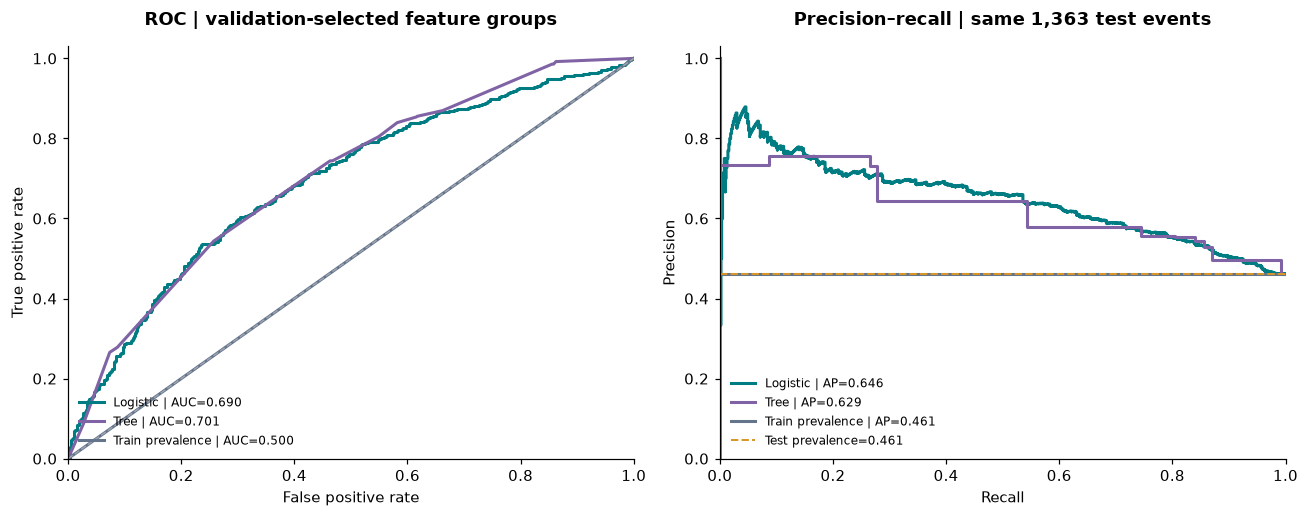

,model,features,test_n,AUC,AP
0,logistic_regression,local+history+flow+calendar,1363,0.689609,0.646056
1,decision_tree,local+history+flow+calendar,1363,0.700748,0.628672
2,train_prevalence,none,1363,0.500000,0.461482


In [17]:
fig,axes=plt.subplots(1,2,figsize=(12,4.8))
roc_records=[]
curve_specs=[('logistic_regression',best_features['logistic_regression'],'Logistic','#007C83'),
             ('decision_tree',best_features['decision_tree'],'Tree','#8063A5'),
             ('train_prevalence','none','Train prevalence','#64748B')]
for model,features,label,color in curve_specs:
    part=predictions.loc[predictions.split.eq('test') & predictions.model.eq(model) & predictions.feature_set.eq(features)]
    assert len(part)==1363 and part.y_true.nunique()==2
    fpr,tpr,_=roc_curve(part.y_true,part.y_score)
    precision,recall,_=precision_recall_curve(part.y_true,part.y_score)
    auc=roc_auc_score(part.y_true,part.y_score)
    ap=average_precision_score(part.y_true,part.y_score)
    axes[0].plot(fpr,tpr,color=color,lw=2,label=f'{label} | AUC={auc:.3f}')
    axes[1].step(recall,precision,where='post',color=color,lw=2,label=f'{label} | AP={ap:.3f}')
    roc_records.append({'model':model,'features':features,'test_n':len(part),'AUC':auc,'AP':ap})
test_prevalence=float(part.y_true.mean())
axes[0].plot([0,1],[0,1],ls='--',color='#9CA3AF',lw=1)
axes[1].axhline(test_prevalence,ls='--',color='#D99729',lw=1.3,label=f'Test prevalence={test_prevalence:.3f}')
axes[0].set(title='ROC | validation-selected feature groups',xlabel='False positive rate',ylabel='True positive rate',xlim=(0,1),ylim=(0,1.03))
axes[1].set(title='Precision–recall | same 1,363 test events',xlabel='Recall',ylabel='Precision',xlim=(0,1),ylim=(0,1.03))
for ax in axes: ax.legend(loc='lower left',fontsize=8,frameon=False)
finish(fig,'07_test_roc_pr')
display(pd.DataFrame(roc_records))

## 13. 混淆矩阵：错误来自哪一类？

正类=30分钟内观察到持续恢复确认。纵轴为真实标签、横轴为预测标签；格子同时给出计数与该真实类别中的比例。
概率模型阈值固定0.5，速度比例规则按冻结配置，趋势规则阈值按验证集Macro-F1选择。
所有矩阵使用相同1,363个测试事件，不能把对角线计数直接当作类别平衡后的表现。

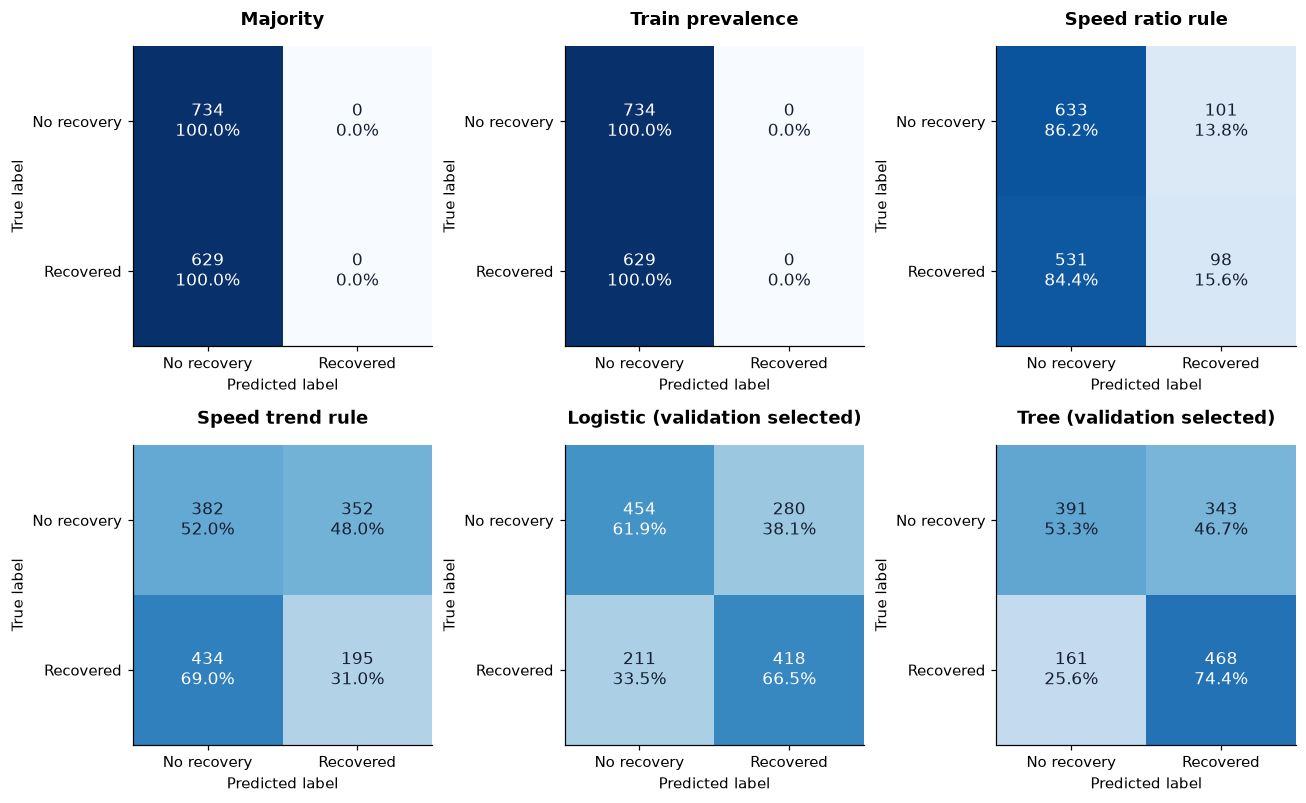

In [18]:
cm_specs=[('majority_class','none','Majority'),('train_prevalence','none','Train prevalence'),
          ('speed_ratio_rule','local_speed_ratio','Speed ratio rule'),('speed_trend_rule','history_rule','Speed trend rule'),
          ('logistic_regression',best_features['logistic_regression'],'Logistic (validation selected)'),
          ('decision_tree',best_features['decision_tree'],'Tree (validation selected)')]
fig,axes=plt.subplots(2,3,figsize=(12,7.4))
for ax,(model,features,title) in zip(axes.flat,cm_specs):
    p=predictions.loc[predictions.split.eq('test') & predictions.model.eq(model) & predictions.feature_set.eq(features)]
    cm=confusion_matrix(p.y_true,p.y_pred,labels=[0,1])
    rates=cm/cm.sum(axis=1,keepdims=True)
    ax.imshow(rates,vmin=0,vmax=1,cmap='Blues')
    for i in range(2):
        for j in range(2):
            ax.text(j,i,f'{cm[i,j]:,}\n{rates[i,j]:.1%}',ha='center',va='center',color='white' if rates[i,j]>.55 else '#172033',fontsize=11)
    ax.set(xticks=[0,1],yticks=[0,1],xticklabels=['No recovery','Recovered'],yticklabels=['No recovery','Recovered'],
           xlabel='Predicted label',ylabel='True label',title=title)
finish(fig,'08_test_confusion_matrices')

## 14. 特征组增益：相同事件、相同split、相同候选预算

S0=本地速度；S1=+近期速度变化；S2=+流量/占有率；S3=+时钟/星期/周末/假期；S4=+温度/风速。
左图是绝对Macro-F1；右图是相对S0的测试Macro-F1变化，0线表示没有变化。
这不是显著性检验；日历组改善不能单独归因于假期，也没有邻路信息的增益结论。

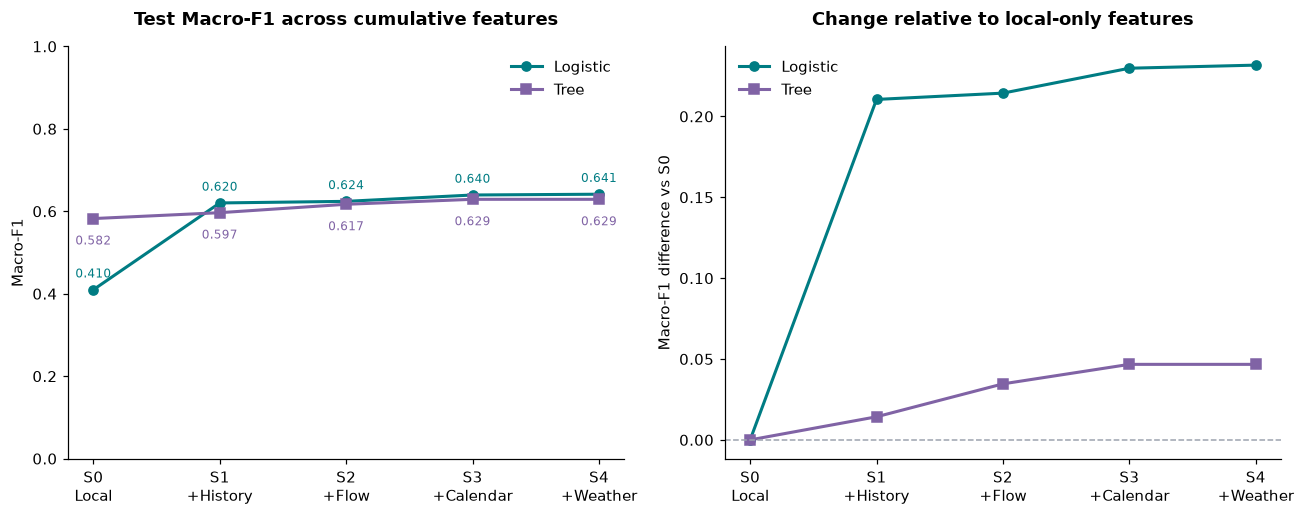

,model,feature_set,reference,metric,raw_delta,improvement
0,logistic_regression,local+history,local,macro_f1,0.2105,0.2105
5,logistic_regression,local+history+flow,local+history,macro_f1,0.0039,0.0039
10,logistic_regression,local+history+flow+calendar,local+history+flow,macro_f1,0.0154,0.0154
15,logistic_regression,local+history+flow+calendar+weather,local+history+flow+calendar,macro_f1,0.0019,0.0019
20,decision_tree,local+history,local,macro_f1,0.0143,0.0143
25,decision_tree,local+history+flow,local+history,macro_f1,0.0204,0.0204
30,decision_tree,local+history+flow+calendar,local+history+flow,macro_f1,0.0121,0.0121
35,decision_tree,local+history+flow+calendar+weather,local+history+flow+calendar,macro_f1,0.0000,0.0000


In [19]:
feature_order=['+'.join(x) for x in FEATURE_SETS]
fig,axes=plt.subplots(1,2,figsize=(12,4.8))
for model,color,marker,label in [('logistic_regression','#007C83','o','Logistic'),('decision_tree','#8063A5','s','Tree')]:
    tab=test_summary.loc[test_summary.model.eq(model)].set_index('feature_set').loc[feature_order]
    values=tab.macro_f1.to_numpy()
    delta=values-values[0]
    axes[0].plot(range(5),values,color=color,marker=marker,lw=2,label=label)
    axes[1].plot(range(5),delta,color=color,marker=marker,lw=2,label=label)
    for i,v in enumerate(values):
        axes[0].annotate(f'{v:.3f}',(i,v),xytext=(0,8 if model=='logistic_regression' else -17),textcoords='offset points',ha='center',fontsize=8,color=color)
axes[1].axhline(0,color='#9CA3AF',ls='--',lw=1)
for ax in axes:
    ax.set_xticks(range(5),['S0\nLocal','S1\n+History','S2\n+Flow','S3\n+Calendar','S4\n+Weather'])
    ax.legend(frameon=False)
axes[0].set(title='Test Macro-F1 across cumulative features',ylabel='Macro-F1',ylim=(0,1))
axes[1].set(title='Change relative to local-only features',ylabel='Macro-F1 difference vs S0')
finish(fig,'09_feature_group_gain')
display(pd.read_csv(OUT/'feature_group_comparisons.csv').query("metric == 'macro_f1'").round(4))

## 15. 逻辑回归系数与树重要性：模型用了什么？

各模型采用自己的验证集最佳特征组。逻辑回归所有入模数值列都按**训练集标准差**缩放；系数表示其余入模变量固定时的log-odds变化，不能当作因果影响。
特征相关性和常量/全缺失列可能使系数难以解释；这里没有估计置信区间。
树的不纯度重要性是模型内部归一化量，受分裂机会与相关特征影响，不是外部有效性或因果证据。

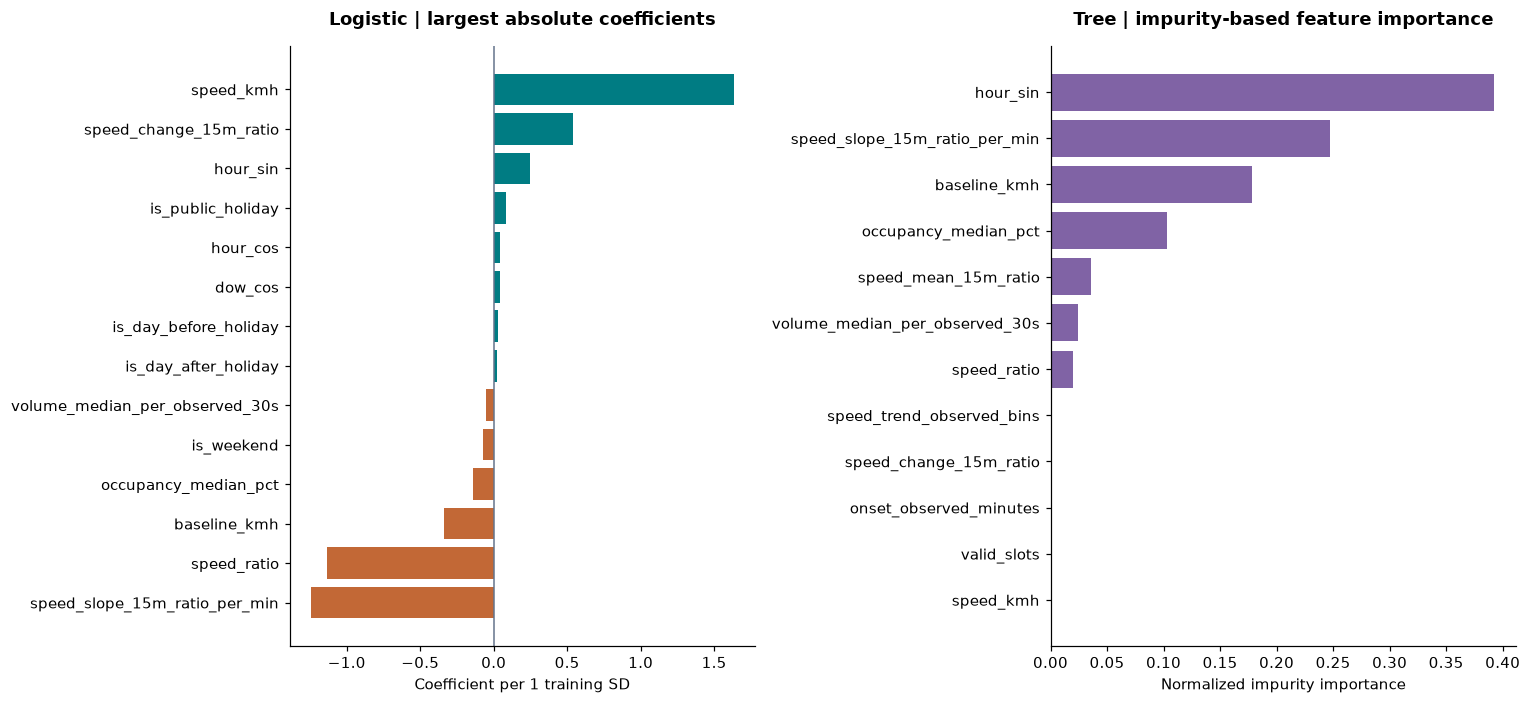

,feature,value,odds_ratio
61,numeric__speed_slope_15m_ratio_per_min,-1.2441,0.2882
55,numeric__speed_ratio,-1.1360,0.3211
56,numeric__baseline_kmh,-0.3392,0.7124
64,numeric__occupancy_median_pct,-0.1401,0.8693
71,numeric__is_weekend,-0.0704,0.9321
63,numeric__volume_median_per_observed_30s,-0.0493,0.9519
74,numeric__is_day_after_holiday,0.0234,1.0237
73,numeric__is_day_before_holiday,0.0263,1.0266
70,numeric__dow_cos,0.0399,1.0407
68,numeric__hour_cos,0.0432,1.0441


Logistic features: local+history+flow+calendar | Tree features: local+history+flow+calendar


In [20]:
log_features=best_features['logistic_regression']
tree_features=best_features['decision_tree']
coef=interpretation.loc[interpretation.model.eq('logistic_regression') & interpretation.feature_set.eq(log_features)].copy()
coef=coef.assign(abs_value=coef.value.abs()).nlargest(14,'abs_value').sort_values('value')
imp=interpretation.loc[interpretation.model.eq('decision_tree') & interpretation.feature_set.eq(tree_features)].copy()
imp=imp.nlargest(12,'value').sort_values('value')
fig,axes=plt.subplots(1,2,figsize=(14,6.5))
axes[0].barh(coef.feature.str.removeprefix('numeric__'),coef.value,color=np.where(coef.value.ge(0),'#007C83','#C26836'))
axes[0].axvline(0,color='#64748B',lw=1)
axes[0].set(title='Logistic | largest absolute coefficients',xlabel='Coefficient per 1 training SD')
axes[1].barh(imp.feature.str.removeprefix('numeric__'),imp.value,color='#8063A5')
axes[1].set(title='Tree | impurity-based feature importance',xlabel='Normalized impurity importance')
finish(fig,'10_coefficients_and_tree_importance')
display(coef[['feature','value','odds_ratio']].round(4))
print('Logistic features:',log_features,'| Tree features:',tree_features)

## 16. 解释结果与适用范围

下面根据本次输出自动生成摘要。比较是描述性的，未构建事件/道路相关性稳健置信区间；不宣称显著性、因果效应或全香港泛化。
当前还未完成“local+已验证邻路”对比，雨量/事故/活动的缺失也不等于它们没有预测价值。

In [21]:
best=chosen.sort_values(['log_loss','feature_count'],kind='stable').iloc[0]
best_test=test_summary.loc[test_summary.model.eq(best.model) & test_summary.feature_set.eq(best.feature_set)].iloc[0]
log_gain=test_summary.loc[test_summary.model.eq('logistic_regression')].set_index('feature_set')
tree_gain=test_summary.loc[test_summary.model.eq('decision_tree')].set_index('feature_set')
text=f"""本次重新训练的验证集选定展示模型为 **{best.model} / {best.feature_set}**。
已知测试标签 **1,363** 个；Macro-F1 **{best_test.macro_f1:.4f}**、balanced accuracy **{best_test.balanced_accuracy:.4f}**、ROC-AUC **{best_test.roc_auc:.4f}**。

从S3加天气到S4，逻辑回归Macro-F1变化 **{log_gain.loc[feature_order[4],'macro_f1']-log_gain.loc[feature_order[3],'macro_f1']:+.4f}**，
树Macro-F1变化 **{tree_gain.loc[feature_order[4],'macro_f1']-tree_gain.loc[feature_order[3],'macro_f1']:+.4f}**。
这只是既定队列上的描述性变化，不能解释为天气因素的显著或因果影响。

所有成绩对应**恢复确认标签**。要回答proposal的恢复开始问题，须先由全组统一定义和随访窗口后重新生成标签、冻结划分并重跑。"""
display(Markdown(text))
(OUT/'report.md').write_text('# New real-data notebook rerun\n\nEXPLORATORY — NOT APPROVED AS FINAL RESULTS\n\n'+text,encoding='utf-8')

本次重新训练的验证集选定展示模型为 **decision_tree / local+history+flow+calendar**。
已知测试标签 **1,363** 个；Macro-F1 **0.6290**、balanced accuracy **0.6384**、ROC-AUC **0.7007**。

从S3加天气到S4，逻辑回归Macro-F1变化 **+0.0019**，
树Macro-F1变化 **+0.0000**。
这只是既定队列上的描述性变化，不能解释为天气因素的显著或因果影响。

所有成绩对应**恢复确认标签**。要回答proposal的恢复开始问题，须先由全组统一定义和随访窗口后重新生成标签、冻结划分并重跑。

397

## 17. 真实输出核验与复现记录

保存逐事件预测、完整指标/混淆矩阵、调参、解释、拟合模型、输入和代码哈希。
最后重新检查全体预测与配对队列、训练期预处理和全部拟合分数；任何不一致即停止。
PNG图保存在本次目录中，Notebook中也嵌入了图像，所以无需启动Python即可查看已有结果。

In [22]:
checks=0
for (model,features,split),p in predictions.groupby(['model','feature_set','split']):
    source=dataset.loc[dataset.split.eq(split) & dataset.label_30m.notna()].set_index('event_id')
    assert p.event_id.is_unique and set(p.event_id)==set(source.index)
    assert np.array_equal(p.y_true.to_numpy(),source.loc[p.event_id,'label_30m'].to_numpy(dtype=int))
    row=summary.loc[summary.model.eq(model)&summary.feature_set.eq(features)&summary.split.eq(split)].iloc[0]
    assert np.isclose(row.macro_f1,f1_score(p.y_true,p.y_pred,average='macro',labels=[0,1],zero_division=0))
    checks+=3
for (kind,features),pipe in fitted.items():
    cols=[c for g in features.split('+') for c in GROUPS[g]]
    train_x=dataset.loc[dataset.split.eq('train')&dataset.label_30m.notna(),cols]
    numeric=pipe.named_steps['preprocess'].named_transformers_['numeric']
    assert np.allclose(numeric.named_steps['impute'].statistics_,train_x.median().to_numpy(),equal_nan=True)
    model={'logistic':'logistic_regression','tree':'decision_tree'}[kind]
    stored=predictions.loc[predictions.model.eq(model)&predictions.feature_set.eq(features)]
    x=dataset.set_index('event_id').loc[stored.event_id,cols]
    assert np.allclose(pipe.predict_proba(x)[:,1],stored.y_score,rtol=0,atol=1e-12)
    checks+=2
    if kind=='logistic':
        expected=numeric.named_steps['impute'].transform(train_x).mean(axis=0)
        assert np.allclose(numeric.named_steps['scale'].mean_,expected)
        checks+=1
# Store snapshots of the exact helper/package code used, including local fixes.
code_dir=RUN/'code'
code_dir.mkdir()
code_hashes={}
for folder in [REPO/'experiments/tianhao',REPO/'src/traffic_recovery/models',REPO/'src/traffic_recovery/external']:
    for source in sorted(folder.glob('*.py')):
        name=source.relative_to(REPO).as_posix()
        target=code_dir/name
        target.parent.mkdir(parents=True,exist_ok=True)
        shutil.copy2(source,target)
        code_hashes[name]=engine.sha(target)
manifest={
    'status':engine.STATUS,'created_at_utc':datetime.now(timezone.utc).isoformat(),
    'source_release':release_meta['url'],'traffic_zip_sha256':release_sha,
    'repository_head':git('rev-parse','HEAD'),'repository_dirty':bool(git('status','--porcelain')),
    'uv_lock_sha256':engine.sha(REPO/'uv.lock'),'plan_sha256':engine.sha(OUT/'predeclared_plan.json'),
    'source_checks_sha256':engine.sha(RUN/'source_checks.json'),
    'software':{'python':platform.python_version(),'pandas':pd.__version__,'numpy':np.__version__,'sklearn':sklearn.__version__},
    'dataset':dataset_manifest,'events':len(dataset),'known_30m':6799,'prediction_rows':len(predictions),'arms':14,
    'checks_passed':checks,'runtime_seconds':time.perf_counter()-STARTED,
    'code_sha256':code_hashes,
    'outputs_sha256':{p.relative_to(RUN).as_posix():engine.sha(p) for p in RUN.rglob('*') if p.is_file() and 'code' not in p.relative_to(RUN).parts},
    'scientific_limits':['recovery confirmation vs proposal start','selected 24 lanes','regional weather proxy',
                         'no verified spatial experiment','no significance/causal claim','previously exposed test set'],
}
(RUN/'rerun_manifest.json').write_text(json.dumps(manifest,indent=2,ensure_ascii=False),encoding='utf-8')
(WORK/'latest_notebook_run.txt').write_text(str(RUN.relative_to(WORK)),encoding='utf-8')
print('Actual training and visualization completed. Checks passed:',checks)
print('Output:',RUN)
print('Figures:',len(list(FIGURES.glob('*.png'))),'| Prediction rows:',len(predictions))
display(pd.DataFrame([{'artifact':p.name,'bytes':p.stat().st_size} for p in sorted(OUT.iterdir()) if p.is_file()]))

Actual training and visualization completed. Checks passed: 151
Output: <local-workspace>/experiments/tianhao/notebook_reruns/real-model-review-20261101T011608Z-db2c17
Figures: 10 | Prediction rows: 95186


,artifact,bytes
0,benchmarks.json,494
1,cohort_summary.csv,136
2,confusion_matrices.csv,2807
3,error_groups.csv,32304
4,event_feature_audit.parquet,2793120
5,event_features.parquet,1027899
6,experiment_contract.json,2771
7,feature_group_comparisons.csv,4301
8,feature_missingness.csv,3226
9,fitted_pipelines.joblib,36069
